# Tech Challenge - Fase 2
## Ajuste de Threshold e Explicabilidade do Modelo

Neste notebook será realizada uma análise do limiar de decisão (threshold) do modelo otimizado pelo Algoritmo Genético.

O objetivo é avaliar se diferentes thresholds podem reduzir a quantidade de falsos negativos, mantendo um equilíbrio adequado entre Recall, Precision e F1-score.

Após a definição do threshold, será utilizada a técnica SHAP para analisar quais características mais influenciam as previsões do modelo.

In [2]:
from pathlib import Path

import json
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEMENTE = 42

np.random.seed(SEMENTE)

print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


In [3]:
def localizar_arquivo(caminhos):
    for caminho in caminhos:
        if caminho.exists():
            return caminho

    raise FileNotFoundError(
        "Nenhum dos caminhos informados foi encontrado."
    )


pasta_atual = Path.cwd()

caminho_dados = localizar_arquivo([
    Path("/app/data/data.csv"),
    pasta_atual / "data" / "data.csv",
    pasta_atual.parent / "data" / "data.csv"
])

caminho_modelo = localizar_arquivo([
    Path("/app/models/modelo_ga_fase2.joblib"),
    pasta_atual / "models" / "modelo_ga_fase2.joblib",
    pasta_atual.parent / "models" / "modelo_ga_fase2.joblib"
])

print("Dataset:")
print(caminho_dados)

print()

print("Modelo:")
print(caminho_modelo)

Dataset:
/app/data/data.csv

Modelo:
/app/models/modelo_ga_fase2.joblib


In [4]:
dados = pd.read_csv(
    caminho_dados
)

df = dados.copy()

df = df.drop(
    columns=[
        "id",
        "Unnamed: 32"
    ],
    errors="ignore"
)

df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

df["diagnosis"] = (
    df["diagnosis"].astype(int)
)

df = (
    df.drop_duplicates()
    .reset_index(drop=True)
)

X = df.drop(
    columns=["diagnosis"]
)

y = df["diagnosis"]

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        stratify=y,
        random_state=SEMENTE
    )
)

print(
    f"Treino: {len(X_train)} registros"
)

print(
    f"Teste: {len(X_test)} registros"
)

print(
    f"Variáveis: {X.shape[1]}"
)

Treino: 455 registros
Teste: 114 registros
Variáveis: 30


In [5]:
modelo_ga = joblib.load(
    caminho_modelo
)

print(
    "Modelo do Algoritmo Genético carregado."
)

print()

print(
    modelo_ga.named_steps["modelo"]
)

Modelo do Algoritmo Genético carregado.

LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000, penalty='l2',
                   random_state=42, solver='liblinear')


## Ajuste do threshold

Por padrão, modelos de classificação binária utilizam um threshold de `0,50`. Isso significa que probabilidades iguais ou superiores a 50% são classificadas como malignas.

Em um contexto de diagnóstico, entretanto, falsos negativos possuem especial importância, pois representam casos realmente malignos classificados como benignos.

Para evitar utilizar o conjunto de teste durante a escolha do threshold, serão geradas probabilidades fora da amostra (out-of-fold) utilizando validação cruzada apenas sobre os dados de treinamento.

O threshold será escolhido utilizando o F2-score, métrica que atribui maior importância ao Recall do que à Precision.

In [6]:
validacao_cruzada = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMENTE
)

probabilidades_validacao = (
    cross_val_predict(
        modelo_ga,
        X_train,
        y_train,
        cv=validacao_cruzada,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]
)

print(
    "Probabilidades out-of-fold geradas."
)

print(
    f"Quantidade: "
    f"{len(probabilidades_validacao)}"
)

Probabilidades out-of-fold geradas.
Quantidade: 455


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logi

In [7]:
thresholds = np.arange(
    0.20,
    0.61,
    0.01
)

resultados_threshold = []

for threshold in thresholds:

    previsoes = (
        probabilidades_validacao
        >= threshold
    ).astype(int)

    resultados_threshold.append({
        "threshold":
            threshold,

        "precision":
            precision_score(
                y_train,
                previsoes,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_train,
                previsoes,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_train,
                previsoes,
                zero_division=0
            ),

        "f2":
            fbeta_score(
                y_train,
                previsoes,
                beta=2,
                zero_division=0
            )
    })


df_threshold = pd.DataFrame(
    resultados_threshold
)

display(
    df_threshold.round(4)
)

,threshold,precision,recall,f1,f2
0,0.20,0.8164,0.9941,0.8966,0.9526
1,0.21,0.8284,0.9941,0.9037,0.9559
2,0.22,0.8276,0.9882,0.9008,0.9513
3,0.23,0.8442,0.9882,0.9106,0.9556
4,0.24,0.8520,0.9824,0.9126,0.9532
5,0.25,0.8608,0.9824,0.9176,0.9554
6,0.26,0.8743,0.9824,0.9252,0.9587
7,0.27,0.8789,0.9824,0.9278,0.9598
8,0.28,0.8836,0.9824,0.9304,0.9609
9,0.29,0.8978,0.9824,0.9382,0.9642


In [8]:
melhor_linha = (
    df_threshold
    .sort_values(
        by=[
            "f2",
            "recall",
            "f1"
        ],
        ascending=False
    )
    .iloc[0]
)

threshold_otimizado = float(
    melhor_linha[
        "threshold"
    ]
)

print(
    "=== THRESHOLD SELECIONADO ==="
)

print(
    f"Threshold: "
    f"{threshold_otimizado:.2f}"
)

print(
    f"Precision: "
    f"{melhor_linha['precision']:.4f}"
)

print(
    f"Recall: "
    f"{melhor_linha['recall']:.4f}"
)

print(
    f"F1-score: "
    f"{melhor_linha['f1']:.4f}"
)

print(
    f"F2-score: "
    f"{melhor_linha['f2']:.4f}"
)

=== THRESHOLD SELECIONADO ===
Threshold: 0.34
Precision: 0.9382
Recall: 0.9824
F1-score: 0.9598
F2-score: 0.9732


In [9]:
comparacao_thresholds = (
    df_threshold[
        df_threshold[
            "threshold"
        ].round(2).isin([
            0.30,
            0.50,
            round(
                threshold_otimizado,
                2
            )
        ])
    ]
    .drop_duplicates(
        subset=["threshold"]
    )
)

display(
    comparacao_thresholds.round(4)
)

,threshold,precision,recall,f1,f2
10,0.30,0.9027,0.9824,0.9408,0.9653
14,0.34,0.9382,0.9824,0.9598,0.9732
30,0.50,0.9760,0.9588,0.9674,0.9622


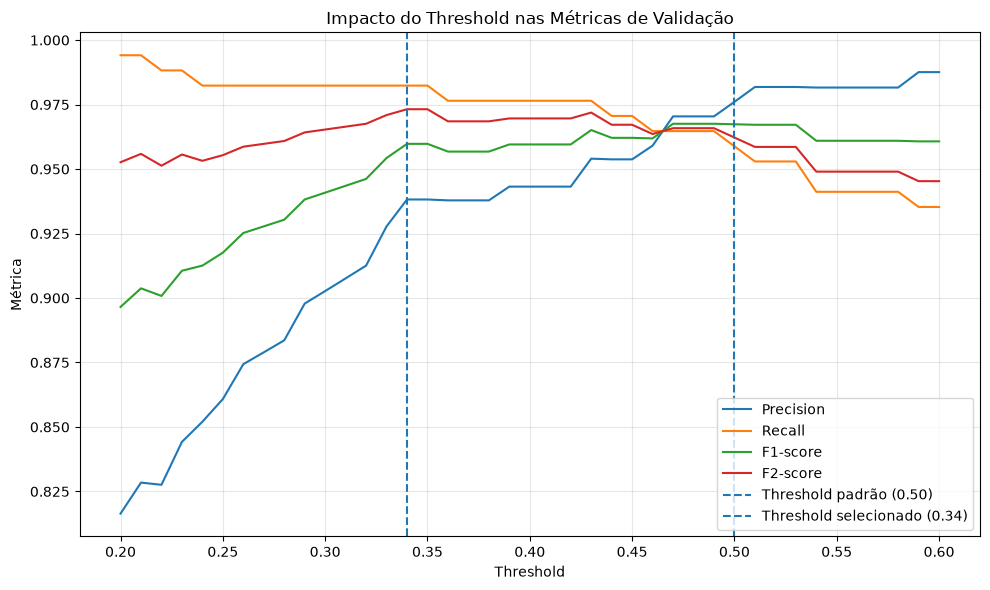

In [10]:
pasta_resultados = localizar_arquivo([
    Path("/app/results"),
    pasta_atual / "results",
    pasta_atual.parent / "results"
])

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["precision"],
    label="Precision"
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["recall"],
    label="Recall"
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["f1"],
    label="F1-score"
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["f2"],
    label="F2-score"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Threshold padrão (0.50)"
)

plt.axvline(
    x=threshold_otimizado,
    linestyle="--",
    label=(
        f"Threshold selecionado "
        f"({threshold_otimizado:.2f})"
    )
)

plt.xlabel(
    "Threshold"
)

plt.ylabel(
    "Métrica"
)

plt.title(
    "Impacto do Threshold "
    "nas Métricas de Validação"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "03_analise_threshold.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Avaliação do threshold no conjunto de teste

Após selecionar o threshold utilizando exclusivamente os dados de treinamento, será realizada a comparação final no conjunto de teste.

Serão comparados o threshold padrão de `0,50` e o threshold selecionado durante a validação.

O objetivo principal é verificar o impacto da alteração sobre Recall, F1-score e quantidade de falsos negativos.

In [11]:
probabilidades_teste = (
    modelo_ga.predict_proba(
        X_test
    )[:, 1]
)

In [12]:
def avaliar_threshold(
    threshold
):

    previsoes = (
        probabilidades_teste
        >= threshold
    ).astype(int)

    matriz = confusion_matrix(
        y_test,
        previsoes
    )

    tn, fp, fn, tp = (
        matriz.ravel()
    )

    return {
        "threshold":
            threshold,

        "accuracy":
            accuracy_score(
                y_test,
                previsoes
            ),

        "precision":
            precision_score(
                y_test,
                previsoes,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_test,
                previsoes,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_test,
                previsoes,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                y_test,
                probabilidades_teste
            ),

        "tn":
            int(tn),

        "fp":
            int(fp),

        "fn":
            int(fn),

        "tp":
            int(tp)
    }

In [13]:
resultado_padrao = (
    avaliar_threshold(
        0.50
    )
)

resultado_otimizado = (
    avaliar_threshold(
        threshold_otimizado
    )
)

comparacao_teste = pd.DataFrame([
    resultado_padrao,
    resultado_otimizado
])

display(
    comparacao_teste.round(4)
)

,threshold,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
0,0.50,0.9912,1.0000,0.9762,0.9880,0.9977,72,0,1,41
1,0.34,0.9474,0.8913,0.9762,0.9318,0.9977,67,5,1,41


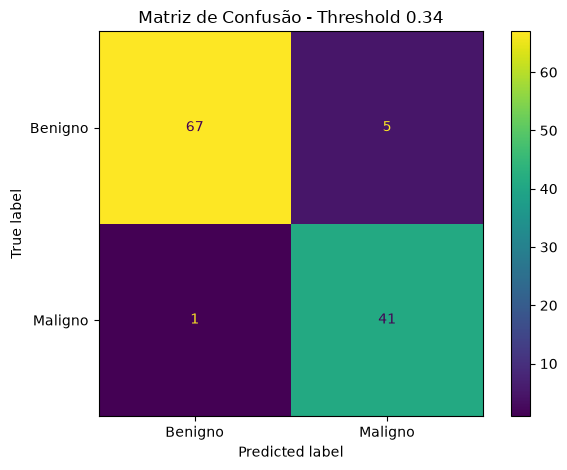

In [14]:
previsoes_otimizadas = (
    probabilidades_teste
    >= threshold_otimizado
).astype(int)

matriz_otimizada = confusion_matrix(
    y_test,
    previsoes_otimizadas
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=
        matriz_otimizada,

    display_labels=[
        "Benigno",
        "Maligno"
    ]
)

disp.plot()

plt.title(
    "Matriz de Confusão - "
    f"Threshold {threshold_otimizado:.2f}"
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "04_matriz_confusao_threshold.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
configuracao_threshold = {
    "threshold_padrao":
        0.50,

    "threshold_otimizado":
        threshold_otimizado,

    "criterio_selecao":
        "Maior F2-score em validação cruzada",

    "resultado_padrao_teste":
        resultado_padrao,

    "resultado_otimizado_teste":
        resultado_otimizado
}


with open(
    pasta_resultados /
    "threshold_otimizado.json",
    "w",
    encoding="utf-8"
) as arquivo:

    json.dump(
        configuracao_threshold,
        arquivo,
        indent=4,
        ensure_ascii=False
    )

print(
    "Configuração do threshold salva."
)

Configuração do threshold salva.


## Explicabilidade com SHAP

Após otimizar o modelo e analisar o threshold de decisão, será utilizada a técnica SHAP para interpretar as previsões.

O SHAP estima a contribuição de cada variável para a saída do modelo, permitindo identificar quais características aumentam ou reduzem a probabilidade de classificação como maligno.

Serão analisadas tanto a importância global das variáveis quanto a explicação de uma previsão individual.

In [16]:
scaler = (
    modelo_ga.named_steps[
        "padronizacao"
    ]
)

regressao = (
    modelo_ga.named_steps[
        "modelo"
    ]
)

X_train_padronizado = pd.DataFrame(
    scaler.transform(
        X_train
    ),
    columns=X_train.columns,
    index=X_train.index
)

X_test_padronizado = pd.DataFrame(
    scaler.transform(
        X_test
    ),
    columns=X_test.columns,
    index=X_test.index
)

print(
    X_train_padronizado.shape
)

print(
    X_test_padronizado.shape
)

(455, 30)
(114, 30)


In [17]:
explicador_shap = (
    shap.LinearExplainer(
        regressao,
        X_train_padronizado
    )
)

valores_shap = (
    explicador_shap(
        X_test_padronizado
    )
)

print(
    "SHAP calculado com sucesso."
)

print(
    valores_shap.values.shape
)

SHAP calculado com sucesso.
(114, 30)


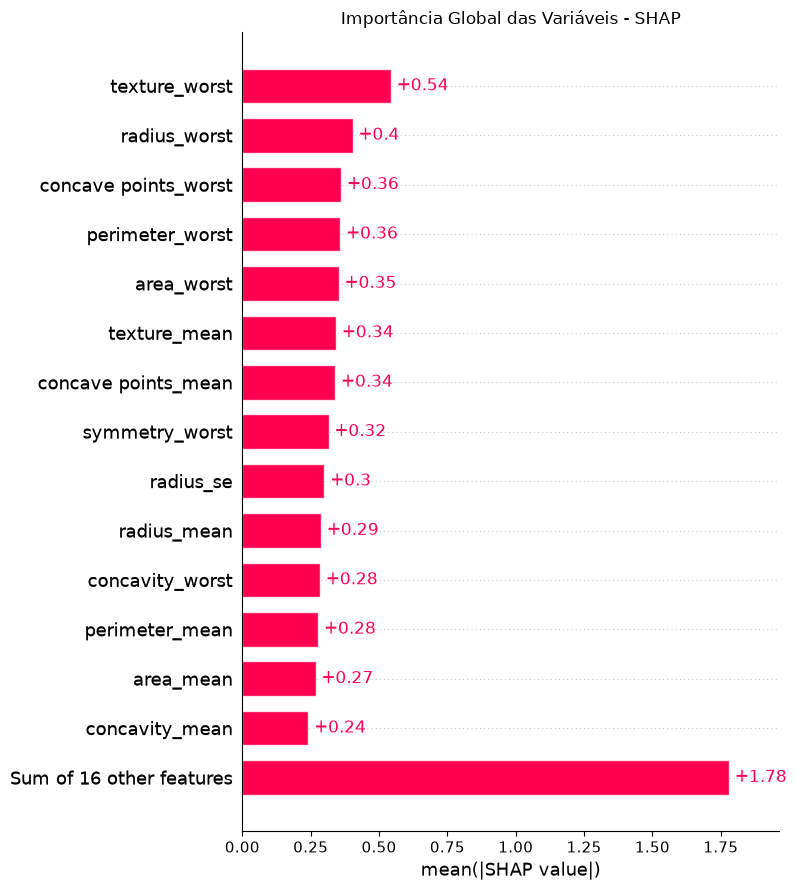

In [18]:
shap.plots.bar(
    valores_shap,
    max_display=15,
    show=False
)

plt.title(
    "Importância Global das Variáveis - SHAP"
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "05_shap_importancia_global.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

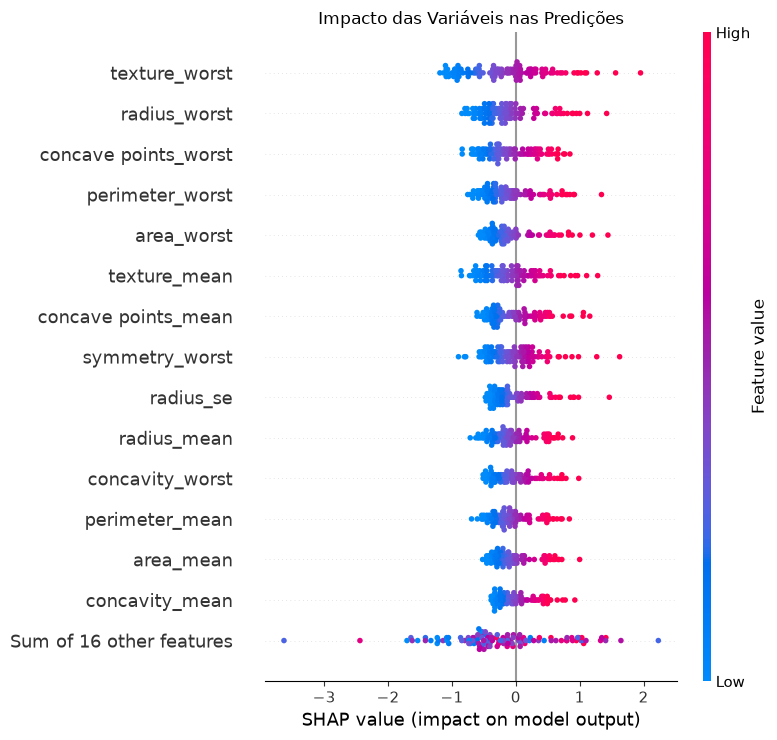

In [19]:
shap.plots.beeswarm(
    valores_shap,
    max_display=15,
    show=False
)

plt.title(
    "Impacto das Variáveis nas Predições"
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "06_shap_impacto_variaveis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
indices_malignos = np.where(
    previsoes_otimizadas == 1
)[0]

indice_exemplo = int(
    indices_malignos[0]
)

print(
    "Índice do exemplo:",
    indice_exemplo
)

print(
    "Probabilidade de malignidade:"
)

print(
    f"{probabilidades_teste[indice_exemplo]:.4f}"
)

print(
    "Classe real:"
)

print(
    int(
        y_test.iloc[
            indice_exemplo
        ]
    )
)

Índice do exemplo: 1
Probabilidade de malignidade:
1.0000
Classe real:
1


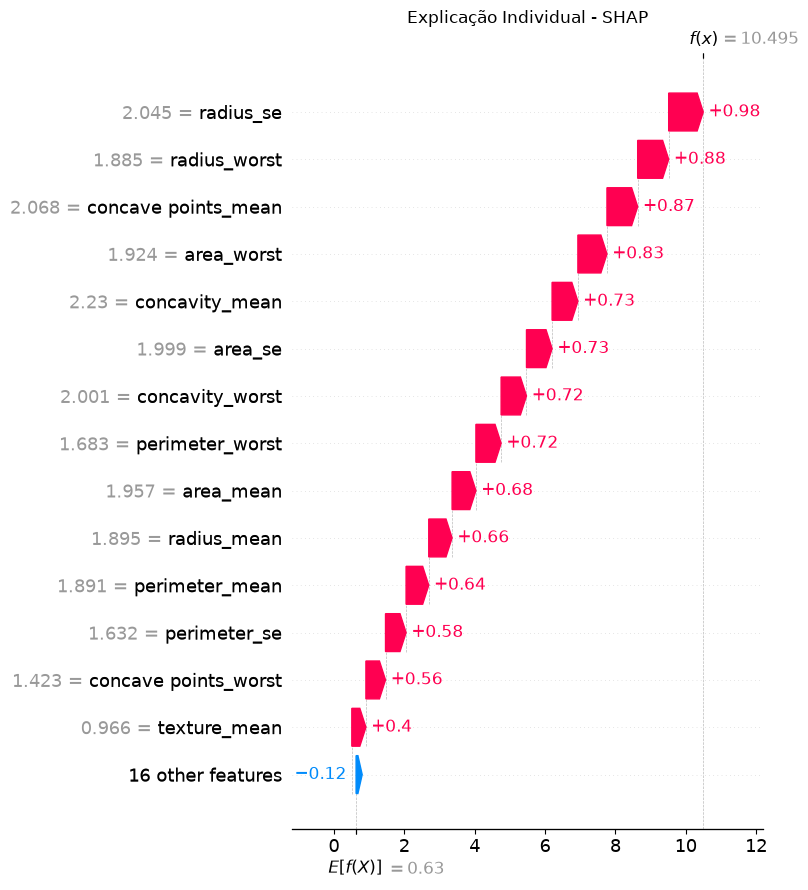

In [22]:
shap.plots.waterfall(
    valores_shap[
        indice_exemplo
    ],
    max_display=15,
    show=False
)

plt.title(
    "Explicação Individual - SHAP"
)

plt.tight_layout()

plt.savefig(
    pasta_resultados /
    "07_shap_explicacao_individual.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
importancia_media = np.abs(
    valores_shap.values
).mean(axis=0)

importancia_shap = pd.DataFrame({
    "variavel":
        X_test.columns,

    "importancia_media_shap":
        importancia_media
})

importancia_shap = (
    importancia_shap
    .sort_values(
        "importancia_media_shap",
        ascending=False
    )
)

display(
    importancia_shap.head(
        15
    )
)

importancia_shap.to_csv(
    pasta_resultados /
    "importancia_variaveis_shap.csv",
    index=False
)

,variavel,importancia_media_shap
21,texture_worst,0.543792
20,radius_worst,0.403651
27,concave points_worst,0.361740
22,perimeter_worst,0.358403
23,area_worst,0.352808
1,texture_mean,0.342873
7,concave points_mean,0.339866
28,symmetry_worst,0.315495
10,radius_se,0.300078
0,radius_mean,0.288084


## Conclusão

A análise de threshold permitiu avaliar o impacto de diferentes limiares de decisão sobre o desempenho do modelo, com atenção especial à redução de falsos negativos.

O threshold foi selecionado utilizando probabilidades out-of-fold produzidas exclusivamente sobre os dados de treinamento, preservando o conjunto de teste para a avaliação final.

Em seguida, a técnica SHAP foi utilizada para interpretar o modelo otimizado pelo Algoritmo Genético, permitindo identificar as variáveis com maior influência global e explicar previsões individuais.

Essas informações serão utilizadas na próxima etapa para fornecer contexto ao LLM e gerar explicações em linguagem natural para os resultados do modelo.